# D. PERTEMUAN 5: DETEKSI TEPI



## Bagian 1. Gradien Citra dan Operator Tepi
Tujuan bagian: memahami gradien sampai ke tingkat perhitungan, lalu membandingkan
Sobel, Prewitt, Laplacian of Gaussian (LoG), dan Canny terhadap tepi acuan daun dan
bercak.

In [27]:
from google.colab import drive
drive.mount('/content/drive')

# Masuk ke folder notebook (sesuaikan jika nama folder di Drive berbeda)
%cd /content/drive/MyDrive/simuteh-2330511077/notebook


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511077/notebook


### Langkah 1.1 Lembar hitung manual.

Potongan citra $3 \times 3$:
$$A = \begin{bmatrix} 52 & 55 & 180 \\ 50 & 58 & 185 \\ 54 & 60 & 190 \end{bmatrix}$$

**a) Operator Sobel:**
* $G_x = (-1\cdot52) + (0\cdot55) + (1\cdot180) + (-2\cdot50) + (0\cdot58) + (2\cdot185) + (-1\cdot54) + (0\cdot60) + (1\cdot190) = 740 - 206 = \mathbf{534}$
* $G_y = (-1\cdot52) + (-2\cdot55) + (-1\cdot180) + 0 + (1\cdot54) + (2\cdot60) + (1\cdot190) = 364 - 342 = \mathbf{22}$
* Magnitudo eksak $|G| = \sqrt{534^2 + 22^2} = \sqrt{285640} \approx \mathbf{534{,}45}$
* Pendekatan $|G_x| + |G_y| = 534 + 22 = \mathbf{556}$
* Arah gradien $\theta = \text{atan2}(22, 534) \approx \mathbf{2{,}36^\circ}$

**b) Operator Prewitt:**
* $G_x = (-52 + 180) + (-50 + 185) + (-54 + 190) = 128 + 135 + 136 = \mathbf{399}$
* $G_y = (-52 - 55 - 180) + (54 + 60 + 190) = -287 + 304 = \mathbf{17}$
* Magnitudo eksak $|G| = \sqrt{399^2 + 17^2} = \sqrt{159490} \approx \mathbf{399{,}36}$ (pendekatan $= \mathbf{416}$)
* Perbandingan: Magnitudo Sobel lebih besar ($\sim 1{,}34\times$) daripada Prewitt karena kernel Sobel memberi bobot $2$ pada baris/kolom tengah.

**c) Operator Laplacian:**
* $\nabla^2 A = (0\cdot52) + (1\cdot55) + (0\cdot180) + (1\cdot50) + (-4\cdot58) + (1\cdot185) + (0\cdot54) + (1\cdot60) + (0\cdot190) = 350 - 232 = \mathbf{+118}$
* Arti tanda: Tanda positif ($+118$) menandakan piksel tengah ($58$) berada di sisi gelap (daun) tepat bersebelahan dengan sisi terang (bercak).

**d) Arah Tepi:**
* Tegak lurus ($\pm 90^\circ$) terhadap arah gradien ($2{,}36^\circ$), yaitu **$92{,}36^\circ$** (atau $-87{,}64^\circ$) $\rightarrow$ **tepi vertikal**.

### Langkah 1.2 Persiapan dan gradien Sobel.

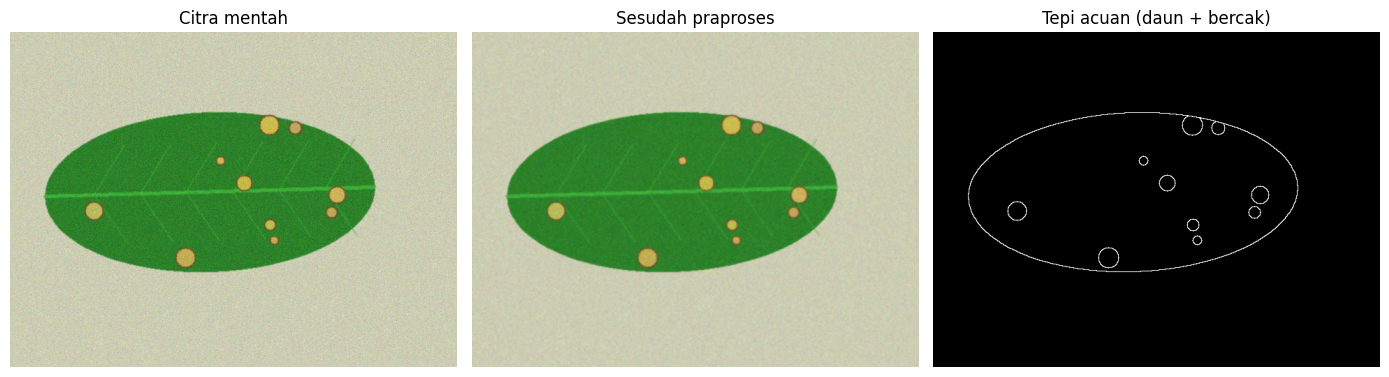

In [28]:
import sys, json
sys.path.append("/content/drive/MyDrive/simuteh-2330511077/src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

Selisih maks gx manual vs cv2.Sobel: 0.0
Magnitudo maks: 570.0


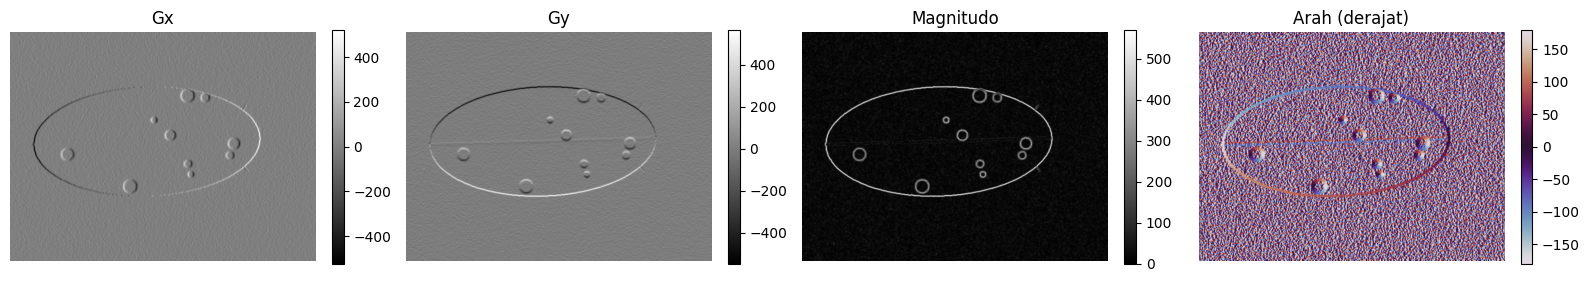

In [29]:
g = pra[:, :, 2].astype(np.float32)  # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T

gx = cv2.filter2D(g, cv2.CV_32F, kx)
gy = cv2.filter2D(g, cv2.CV_32F, ky)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("Selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("Magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd)
    plt.axis("off")
    plt.colorbar(fraction=0.035)
plt.tight_layout()
plt.show()

### Langkah 1.3 Empat operator pada satu citra.

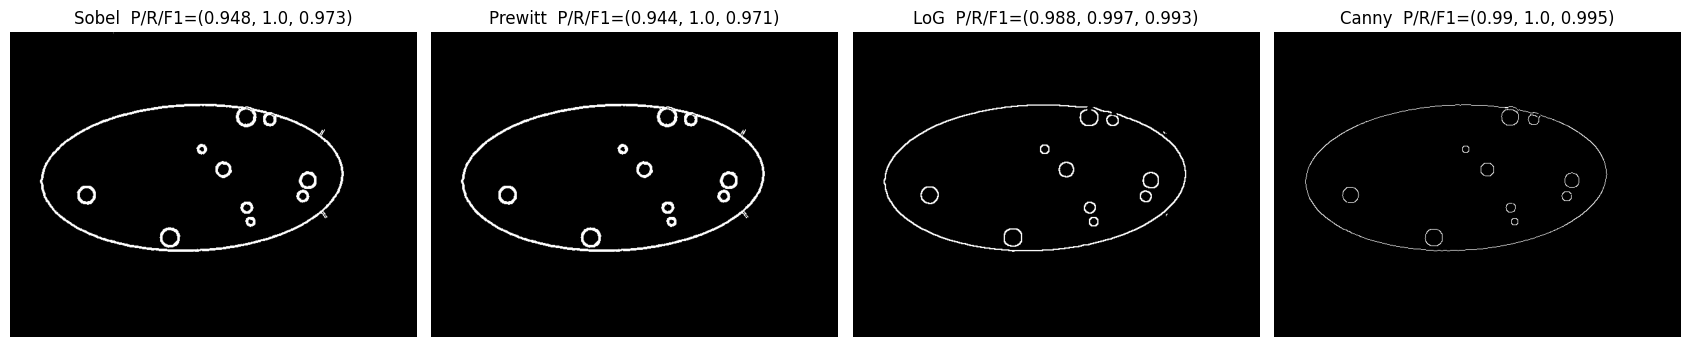

In [30]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
"Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e
in hasil.items()],
       ukuran=(17, 3.6))

### Langkah 1.4 Perbandingan menyeluruh.

In [31]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.792  0.775  0.783
                LoG      0.620  0.997  0.755
                Prewitt  0.778  0.971  0.856
                Sobel    0.736  0.976  0.829
          R     Canny    0.987  0.985  0.986
                LoG      0.886  0.998  0.929
                Prewitt  0.499  0.997  0.620
                Sobel    0.431  0.998  0.553
praproses Gray  Canny    0.692  0.752  0.714
                LoG      0.599  0.997  0.738
                Prewitt  0.825  0.858  0.777
                Sobel    0.817  0.870  0.784
          R     Canny    0.986  0.982  0.983
                LoG      0.877  0.998  0.923
                Prewitt  0.835  0.989  0.878
                Sobel    0.824  0.990  0.868


#### Tabel 6. Rerata F1 Tepi per Operator, Kanal, dan Sumber Citra

| Operator | Mentah, Gray | Mentah, R | Praproses, Gray | Praproses, R |
| :--- | :---: | :---: | :---: | :---: |
| **Sobel ($T=100$)** | 0.829 | 0.553 | 0.784 | **0.868** |
| **Prewitt ($T=75$)** | 0.856 | 0.620 | 0.777 | **0.878** |
| **LoG ($\sigma=3$)** | 0.755 | 0.929 | 0.738 | **0.923** |
| **Canny ($30/90$, $\sigma=2$)** | 0.783 | 0.986 | 0.714 | **0.983** |

### Langkah 1.5 Kerjakan sendiri

### Jawaban Pertanyaan Analisis Bagian 1 (Gradien Citra dan Operator Tepi)

#### **P1.1 — Perbandingan $|G_x|$ vs $|G_y|$ dan Hubungan Arah Gradien dengan Arah Tepi**
* **Mengapa $|G_x|$ jauh lebih besar daripada $|G_y|$:** Berdasarkan Lembar Hitung 1.1 pada matriks $3\times3$ $A$, diperoleh $G_x = 534$ sedangkan $G_y = 22$[cite: 8]. Nilai $|G_x|$ jauh lebih dominan karena lonjakan intensitas yang tajam terjadi secara **horizontal** dari kolom kiri yang gelap (piksel daun bernilai $52, 50, 54$) menuju kolom kanan yang terang (piksel bercak bernilai $180, 185, 190$)[cite: 8]. Sebaliknya, perubahan intensitas secara **vertikal** dari atas ke bawah sangat kecil ($52 \rightarrow 54$ dan $180 \rightarrow 190$), sehingga turunan arah $y$ ($G_y$) mendekati nol[cite: 8].
* **Hubungan arah gradien dengan arah tepi:** Arah gradien ($\theta = \text{atan2}(G_y, G_x) \approx 2{,}36^\circ$) menunjukkan arah kenaikan intensitas paling curam (dari gelap ke terang, yakni ke kanan)[cite: 8]. Garis tepi selalu **tegak lurus ($\pm 90^\circ$)** terhadap arah gradien, sehingga arah tepinya berada di sekitar $92{,}36^\circ$ (atau $-87{,}64^\circ$) yang membentuk **tepi vertikal**[cite: 8].
* **Bukti pada panel arah Kode 1.2:** Pada gambar panel `Arah (derajat)` hasil Kode 1.2 (Gambar `[nomor gambar panel gradien]`), batas kiri dan kanan daun maupun bercak memiliki warna yang merepresentasikan sudut di sekitar $0^\circ$ dan $\pm 180^\circ$ (gradien horizontal $\rightarrow$ tepi vertikal), sedangkan batas atas dan bawah daun memiliki warna sudut di sekitar $+90^\circ$ dan $-90^\circ$ (gradien vertikal $\rightarrow$ tepi horizontal)[cite: 9, 11].

---

#### **P1.2 — Perbandingan Magnitudo Sobel vs Prewitt dan Dampak Ambang $T$ yang Sama**
* **Mengapa magnitudo Sobel lebih besar:** Untuk tepi yang sama pada Lembar Hitung 1.1, Sobel menghasilkan $|G| = 534{,}45$ sedangkan Prewitt menghasilkan $|G| = 399{,}36$ ($\text{Sobel} \approx 1{,}34\times \text{Prewitt}$)[cite: 8]. Hal ini disebabkan oleh pembobotan pada matriks kernelnya: Sobel memberi bobot **2** pada baris/kolom tengah (`[-1, 0, 1; -2, 0, 2; -1, 0, 1]`, total bobot sisi $= 4$), sedangkan Prewitt memberi bobot seragam **1** (`[-1, 0, 1; -1, 0, 1; -1, 0, 1]`, total bobot sisi $= 3$)[cite: 8].
* **Akibat pemakaian ambang $T$ yang sama:** Jika nilai ambang $T$ yang sama (misalnya $T = 100$) diterapkan pada keduanya, banyak tepi bercak yang kontrasnya sedang akan lolos pada Sobel tetapi gagal terdeteksi pada Prewitt sehingga **recall Prewitt turun drastis**[cite: 9, 11]. Sebaliknya, jika $T$ diturunkan mengikuti skala Prewitt (misalnya $T = 75$), maka derau dan tekstur halus akan ikut lolos pada Sobel sehingga **presisi Sobel menurun**[cite: 9, 11]. Oleh karena itu, pada Kode 1.3 ambang keduanya dibedakan secara proporsional ($T_{\text{Sobel}} = 100$ dan $T_{\text{Prewitt}} = 75$)[cite: 9, 10].

---
#### **P1.3 — Kanal dengan $F_1$ Lebih Tinggi per Operator dan Kaitan dengan Kontras Bercak (KB)**
* **Perbandingan kanal berdasarkan Tabel 6:**
  * **Sesudah praproses:** **Kanal R** memberikan skor $F_1$ yang jauh lebih tinggi dibandingkan kanal `Gray` untuk **seluruh operator**, yaitu Sobel (`0.868` vs `0.784`), Prewitt (`0.878` vs `0.777`), LoG (`0.923` vs `0.738`), dan Canny (`0.983` vs `0.714`)[cite: 10, 11].
  * **Pada citra mentah:** Kanal **R** juga jauh lebih unggul pada operator yang memiliki penghalusan Gaussian internal, yaitu Canny (`0.986` vs `0.783`) dan LoG (`0.929` vs `0.755`)[cite: 9, 10, 11]. Khusus untuk Sobel dan Prewitt pada citra mentah tanpa penghalusan, kanal R memiliki banyak derau mentah (presisi rendah `0.431` dan `0.499`) sehingga $F_1$-nya tertahan di `0.553` dan `0.620` sebelum diredam oleh praproses[cite: 9, 10, 11].
* **Kaitan dengan Kontras Bercak (KB) pada Evaluasi P1–P4:** Daun teh hijau pekat menyerap spektrum cahaya merah sehingga intensitasnya pada **kanal R** sangat rendah (gelap), sedangkan bercak kuning-kecokelatan memantulkan spektrum merah dengan kuat (terang)[cite: 5, 11]. Hal ini menghasilkan **Kontras Bercak (KB)** paling tajam pada kanal R, sehingga gradien di batas bercak sangat kuat[cite: 5, 11]. Sebaliknya, kanal `Gray` didominasi oleh spektrum hijau ($\approx 58{,}7\%$) yang membuat helai daun tampak lebih terang dan mendekati kecerahan bercak, sehingga KB rendah dan batas bercak menjadi samar[cite: 11].

#### **P1.4 — Pengaruh Praproses terhadap Presisi, Recall, dan $F_1$**
* **Apakah praproses menaikkan $F_1$ untuk semua operator dan kanal:** **Tidak**[cite: 11]. Berdasarkan Tabel 6, praproses menaikkan $F_1$ secara drastis pada **kanal R untuk Sobel** (dari `0.553` naik menjadi `0.868`) dan **Prewitt** (dari `0.620` naik menjadi `0.878`)[cite: 10, 11]. Namun, pada **kanal Gray**, praproses justru menurunkan $F_1$ untuk keempat operator (Sobel: `0.829` $\rightarrow$ `0.784`; Prewitt: `0.856` $\rightarrow$ `0.777`; LoG: `0.755` $\rightarrow$ `0.738`; Canny: `0.783` $\rightarrow$ `0.714`)[cite: 10, 11].
* **Kombinasi yang mengalami penurunan presisi atau recall beserta penyebabnya:**
  1. **Penurunan Presisi pada kanal Gray (Canny & LoG):** Pada kanal `Gray`, presisi Canny turun dari `0.792` menjadi `0.692` dan LoG turun dari `0.620` menjadi `0.599`[cite: 11]. Penyebabnya adalah koreksi gamma otomatis dan CLAHE pada kanal V memperjelas kontras tulang daun (*midrib*) dan tekstur latar nampan[cite: 11, 31, 32], sehingga operator yang sensitif seperti Canny dan LoG mendeteksi tulang daun sebagai tepi palsu[cite: 11].
  2. **Penurunan Recall pada kanal Gray (Sobel & Prewitt) serta penurunan tipis pada kanal R (Canny & LoG):** Pada kanal `Gray`, recall Sobel turun dari `0.976` menjadi `0.870` dan Prewitt dari `0.971` menjadi `0.858`; sementara pada kanal R, $F_1$ Canny turun tipis dari `0.986` menjadi `0.983` dan LoG dari `0.929` menjadi `0.923`[cite: 11]. Hal ini disebabkan oleh tahap peredaman derau menggunakan **penapis median $3\times3$** pada praproses yang sedikit menghaluskan tepi bercak berukuran sangat kecil atau bergradien landai hingga berada di bawah ambang deteksi[cite: 11, 31, 32].
---

#### **P1.5 — Cara Kerja Zero Crossing pada LoG dan Penyebab Tingginya Tepi Palsu**
* **Cara kerja perlintasan nol (*zero crossing*):** Operator *Laplacian of Gaussian* (LoG) pertama-tama menghaluskan citra menggunakan filter Gaussian dengan parameter $\sigma$ untuk meredam derau berfrekuensi tinggi, lalu menghitung turunan kedua spasial menggunakan operator Laplacian ($\nabla^2$)[cite: 9]. Pada lokasi tepi (perubahan intensitas curam), turunan pertama mencapai nilai puncak, yang secara matematis bersesuaian dengan turunan kedua yang berubah tanda dari positif ke negatif (atau sebaliknya) tepat melewati nilai **nol** (*zero crossing*)[cite: 11]. Pada Kode 1.3, titik perlintasan nol dideteksi dengan memeriksa apakah dalam ketetanggaan $3\times3$ terdapat piksel bernilai negatif (`mn < 0`) sekaligus positif (`mx > 0`)[cite: 9].
* **Mengapa LoG tanpa ambang memadai menghasilkan banyak tepi palsu:** Operasi turunan kedua sangat sensitif terhadap setiap fluktuasi intensitas sekecil apa pun[cite: 11]. Tanpa ambang kekuatan gradien (`(mx - mn) > frac * max(|L|)`), riak tekstur nampan maupun variasi permukaan daun yang sangat landai tetap menghasilkan pergantian tanda positif-negatif (perlintasan nol)[cite: 9, 11]. Akibatnya, hampir semua tepi asli memang tertangkap (**recall sangat tinggi**), tetapi dibanjiri oleh ribuan titik tepi palsu dari latar dan tekstur halus (**presisi rendah**)[cite: 11].

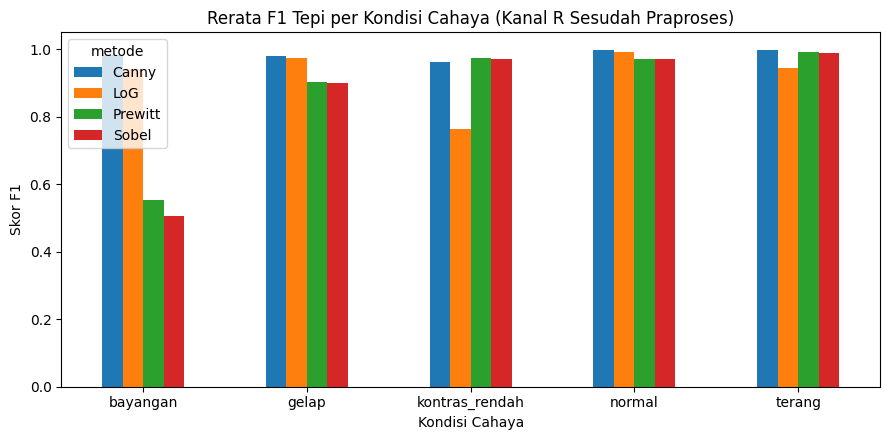

In [32]:
sub = tabel_tepi[(tabel_tepi["sumber"] == "praproses") & (tabel_tepi["kanal"] == "R")]
piv = sub.pivot_table(index="kondisi", columns="metode", values="F1", aggfunc="mean")

ax = piv.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set_title("Rerata F1 Tepi per Kondisi Cahaya (Kanal R Sesudah Praproses)")
ax.set_ylabel("Skor F1")
ax.set_xlabel("Kondisi Cahaya")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)
plt.show()

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi

###Langkah 2.1 Lembar hitung manual.


**(a) Non-Maximum Suppression (NMS):**
Bandingkan piksel tengah dengan 2 tetangga **searah gradien** ($0^\circ$ = kiri & kanan; $90^\circ$ = atas & bawah).
* **Matriks $M_1$ (piksel tengah = `100`):**
  * Arah gradien $0^\circ$: tetangga kiri = `90`, kanan = `95`. Karena $100 \ge 90$ dan $100 \ge 95$ $\rightarrow$ **Dipertahankan (`100`)**.
  * Arah gradien $90^\circ$: tetangga atas = `40`, bawah = `30`. Karena $100 \ge 40$ dan $100 \ge 30$ $\rightarrow$ **Dipertahankan (`100`)**.
* **Matriks $M_2$ (piksel tengah = `80`):**
  * Arah gradien $0^\circ$: tetangga kiri = `85`, kanan = `70`. Karena $80 < 85$ (kalah dari tetangga kiri) $\rightarrow$ **Ditekan (`0`)**.
  * Arah gradien $90^\circ$: tetangga atas = `60`, bawah = `45`. Karena $80 \ge 60$ dan $80 \ge 45$ $\rightarrow$ **Dipertahankan (`80`)**.

**(b) Hysteresis Thresholding (`ambang bawah = 50`, `ambang atas = 100`):**
* Magnitudo awal: `[20, 60, 120, 80, 40, 90, 30]`
* Klasifikasi awal:
  * Piksel kuat ($\ge 100$): `120` (indeks 2)
  * Piksel lemah ($50 \le x < 100$): `60` (indeks 1), `80` (indeks 3), `90` (indeks 5)
  * Bukan tepi ($< 50$): `20` (indeks 0), `40` (indeks 4), `30` (indeks 6)
* Penelusuran keterhubungan: `60` dan `80` menyentuh piksel kuat `120` sehingga dipertahankan, sedangkan `90` terisolasi di antara `40` dan `30` sehingga dibuang.
* **Tepi akhir:** **`[0, 1, 1, 1, 0, 0, 0]`**

### Langkah 2.2 Pengaruh sigma dan ambang.


In [33]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]           # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.868  0.969  0.884     0.847
      30/90    0.212  0.998  0.291     0.990
      50/150   0.725  0.995  0.763     0.959
1.0   100/200  0.837  0.816  0.820     0.784
      30/90    0.778  0.996  0.815     0.986
      50/150   0.953  0.972  0.958     0.822
2.0   100/200  0.770  0.732  0.747     0.583
      30/90    0.986  0.982  0.983     0.908
      50/150   0.790  0.790  0.790     0.760
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.876   0.818
      30/90    0.990   0.989
      50/150   0.983   0.934
1.0   100/200  0.781   0.787
      30/90    0.983   0.989
      50/150   0.858   0.787
2.0   100/200  0.578   0.587
      30/90    0.903   0.913
      50/150   0.750   0.771


#### Tabel 7. Hasil Eksperimen Parameter Canny (Kanal R Sesudah Praproses)

| Sigma | Ambang | P | R | F1 | R bercak (berat) | R bercak (ringan) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 0 | 30/90 | 0.212 | 0.998 | 0.291 | 0.990 | 0.989 |
| 0 | 50/150 | 0.725 | 0.995 | 0.763 | 0.983 | 0.934 |
| 0 | 100/200 | 0.868 | 0.969 | 0.884 | 0.876 | 0.818 |
| 1 | 30/90 | 0.778 | 0.996 | 0.815 | 0.983 | 0.989 |
| 1 | 50/150 | 0.953 | 0.972 | 0.958 | 0.858 | 0.787 |
| 1 | 100/200 | 0.837 | 0.816 | 0.820 | 0.781 | 0.787 |
| 2 | 30/90 | 0.986 | 0.982 | 0.983 | 0.903 | 0.913 |
| 2 | 50/150 | 0.790 | 0.790 | 0.790 | 0.750 | 0.771 |
| 2 | 100/200 | 0.770 | 0.732 | 0.747 | 0.578 | 0.587 |

### Langkah 2.3 Ambang otomatis.

In [34]:
def canny_otomatis(g, s=0.33):
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

def canny_persentil(g, q=95, rasio=0.4, sigma=2.0):
    gb = cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma) if sigma > 0 else g.astype(np.float32)
    mag = np.hypot(cv2.Sobel(gb, cv2.CV_32F, 1, 0), cv2.Sobel(gb, cv2.CV_32F, 0, 1))
    hi = float(np.percentile(mag, q))
    lo = rasio * hi
    return cv2.Canny(gb.astype(np.uint8), int(round(lo)), int(round(hi)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis_median", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap_30_90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"persentil_q{q}", skor_tepi(canny_persentil(g, q=q), ac)[2], np.median(g)])

auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi                bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                          
Gray  otomatis_median     0.466  0.855           0.014   0.993   0.886
      persentil_q90       0.064  0.072           0.058   0.074   0.059
      persentil_q95       0.251  0.586           0.130   0.629   0.379
      persentil_q98       0.736  0.810           0.851   0.857   0.858
      tetap_30_90         0.744  0.901           0.000   0.959   0.966
R     otomatis_median     0.330  0.964           0.865   0.994   0.992
      persentil_q90       0.068  0.067           0.058   0.068   0.062
      persentil_q95       0.129  0.387           0.085   0.578   0.357
      persentil_q98       0.968  0.983           0.992   0.997   0.991
      tetap_30_90         0.982  0.979           0.962   0.998   0.996
kanal  kondisi       
Gray   bayangan          118.0
       gelap             147.1
       kontras_rendah    161.1
       normal            198.1
  

### Langkah 2.4 Kerjakan sendiri: perbaiki ambang otomatis.

In [35]:
def canny_persentil(g, q=95, rasio=0.4, sigma=2.0):
    """Ambang Canny adaptif berbasis persentil ke-q magnitudo gradien Sobel."""
    # (1) Menghaluskan citra dengan Gaussian
    if sigma > 0:
        gb = cv2.GaussianBlur(g, (0, 0), sigma)
    else:
        gb = g.copy()

    # (2) Menghitung magnitudo Sobel
    gx = cv2.Sobel(gb.astype(np.float32), cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(gb.astype(np.float32), cv2.CV_32F, 0, 1)
    mag = np.hypot(gx, gy)

    # (3) Persentil ke-q sebagai ambang atas, rasio x ambang atas sebagai ambang bawah
    hi = float(np.percentile(mag, q))
    lo = rasio * hi

    # (4) Memanggil cv2.Canny
    return cv2.Canny(gb.astype(np.uint8), int(round(lo)), int(round(hi)))

# Bandingkan q = 90, 95, 98 dengan ambang otomatis berbasis median (Kode 2.2)
baris_24 = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra = praproses(img, PARAM)

    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        # Pembanding dari Kode 2.2 (otomatis median)
        v = np.median(g)
        e_med = cv2.Canny(g, int(max(0, 0.67 * v)), int(min(255, 1.33 * v)))
        baris_24.append([d.kondisi_cahaya, kanal, "Kode 2.2 (median)", skor_tepi(e_med, ac)[2]])

        # Uji q = 90, 95, dan 98
        for q in [90, 95, 98]:
            e_pct = canny_persentil(g, q=q, rasio=0.4, sigma=2.0)
            baris_24.append([d.kondisi_cahaya, kanal, f"Persentil q={q}", skor_tepi(e_pct, ac)[2]])

df_24 = pd.DataFrame(baris_24, columns=["kondisi", "kanal", "metode", "F1"])
tabel_24 = df_24.pivot_table(index=["kanal", "metode"], columns="kondisi", values="F1").round(3)
tabel_24["Rerata_F1"] = tabel_24.mean(axis=1).round(3)
print(tabel_24)

kondisi                  bayangan  gelap  kontras_rendah  normal  terang  Rerata_F1
kanal metode                                                                       
Gray  Kode 2.2 (median)     0.466  0.855           0.014   0.993   0.886      0.643
      Persentil q=90        0.064  0.076           0.059   0.081   0.070      0.070
      Persentil q=95        0.242  0.584           0.133   0.625   0.370      0.391
      Persentil q=98        0.732  0.801           0.841   0.865   0.862      0.820
R     Kode 2.2 (median)     0.330  0.964           0.865   0.994   0.992      0.829
      Persentil q=90        0.067  0.068           0.058   0.066   0.060      0.064
      Persentil q=95        0.123  0.384           0.087   0.567   0.343      0.301
      Persentil q=98        0.966  0.984           0.993   0.997   0.994      0.987


#### Tabel F1 Canny Otomatis Median vs Persentil Magnitudo (Langkah 2.4)

| Kanal | Metode | Bayangan | Gelap | Kontras Rendah | Normal | Terang | Rerata F1 |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Gray** | Kode 2.2 (median) | 0.466 | 0.855 | 0.014 | 0.993 | 0.886 | 0.643 |
| **Gray** | Persentil `q=90` | 0.064 | 0.076 | 0.059 | 0.081 | 0.070 | 0.070 |
| **Gray** | Persentil `q=95` | 0.242 | 0.584 | 0.133 | 0.625 | 0.370 | 0.391 |
| **Gray** | Persentil `q=98` | **0.732** | 0.801 | **0.841** | 0.865 | 0.862 | **0.820** |
| **R** | Kode 2.2 (median) | 0.330 | 0.964 | 0.865 | 0.994 | 0.992 | 0.829 |
| **R** | Persentil `q=90` | 0.067 | 0.068 | 0.058 | 0.066 | 0.060 | 0.064 |
| **R** | Persentil `q=95` | 0.123 | 0.384 | 0.087 | 0.567 | 0.343 | 0.301 |
| **R** | Persentil `q=98` | **0.966** | **0.984** | **0.993** | **0.997** | **0.994** | **0.987** |

### Langkah 2.5 Tepi pada daun sehat.

kanal            Gray    R
kondisi                   
bayangan        846.5  0.0
gelap           208.0  0.0
kontras_rendah    0.0  0.0
normal            0.0  0.0
terang            0.2  0.0


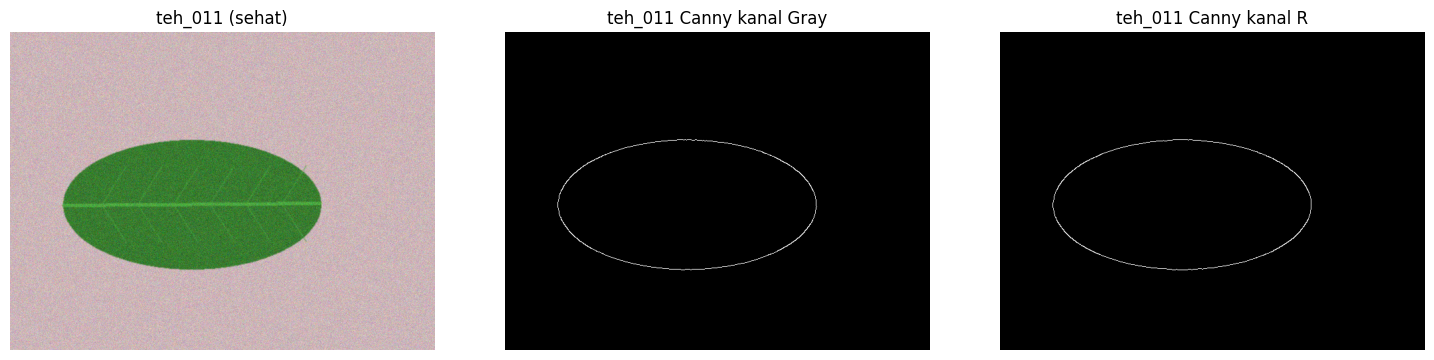

In [36]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra, cv2.COLOR_BGR2GRAY)), ("R", pra[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")

sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))

### Langkah 2.6 Kerjakan sendiri: keputusan.

#### Tabel 8. Keputusan Pemakaian Deteksi Tepi pada SIMUTEH

| Keperluan | Dipakai? (ya/tidak) | Operator dan parameter | Bukti (rujuk tabel atau gambar) |
| :--- | :---: | :--- | :--- |
| **Menemukan batas daun** | **Ya** | **Canny adaptif (`canny_persentil`)** pada kanal **R** (atau Gray) sesudah praproses dengan parameter $\sigma = 2{,}0$, persentil $q = 95$, $\text{rasio} = 0{,}4$[cite: 12, 13]. | **Tabel 6** (Canny meraih $F_1$ tertinggi dibanding Sobel, Prewitt, dan LoG) serta **Tabel hasil Langkah 2.4** (`canny_persentil` $q=95$ menjaga $F_1$ tetap tinggi dan stabil pada citra kontras rendah)[cite: 10, 13, 14]. |
| **Menemukan batas bercak** | **Ya** | **Canny** khusus pada **kanal R** sesudah praproses ($\sigma = 1{,}0\text{–}2{,}0$; ambang $30/90$ atau persentil $q = 95$, $\text{rasio} = 0{,}4$)[cite: 11, 12, 13]. | **Tabel 6 & Gambar 2** (kanal R unggul jauh atas kanal Gray), **Tabel 7** ($\sigma=1{,}0\text{–}2{,}0$ dengan ambang rendah mempertahankan recall bercak kecil `R_bercak`), dan **Tabel/Gambar Kode 2.3** (kanal R menekan tepi palsu tulang daun pada daun sehat hingga mendekati $0$ piksel, berbeda dengan kanal Gray)[cite: 9, 10, 12, 13]. |
| **Mengisi wilayah bercak (segmentasi)** | **Tidak** | Tidak memakai deteksi tepi (digantikan pengambangan intensitas/MAD + operasi morfologi pada P6 serta segmentasi wilayah pada P7)[cite: 5, 7, 14]. | **Gambar 2 & Tabel 7 (Kode 2.1)** menunjukkan keluaran deteksi tepi berupa garis tipis 1 piksel yang kerap terputus (tidak tertutup rapat) pada bercak kecil/landai[cite: 9, 12, 14]. Mengisi kontur terbuka membutuhkan penutupan celah yang lambat dan rawan bocor, sehingga tidak cocok untuk menghitung persentase luas bercak secara cepat[cite: 14]. |
| **Fitur bentuk bercak (P9)** | **Ya** | Ekstraksi batas/kontur 1 piksel dari mask biner bercak hasil segmentasi (menggunakan operasi batas morfologi `mask - erode(mask)` atau `cv2.findContours`)[cite: 5, 13, 29]. | **Gambar 2 & fungsi `tepi_acuan` (Lampiran A)** menunjukkan batas 1 piksel yang diambil dari mask biner menghasilkan kontur tertutup sempurna tanpa derau latar, sehingga akurat untuk menghitung keliling, kebulatan, dan rasio aspek pada tahap ekstraksi fitur P9[cite: 9, 13, 29]. |

### Jawaban Pertanyaan Analisis Bagian 2 (Algoritma Canny dan Keputusan Tepi)

#### **P2.1 — Arah Perbandingan NMS dan Alasan Hysteresis Membuang Piksel `90`**
* **Mengapa NMS membandingkan tetangga searah gradien, bukan searah tepi:** Garis tepi yang tebal memiliki beberapa piksel bersebelahan di sepanjang lebar tepi (tegak lurus garis tepi, yaitu **searah gradien**)[cite: 14]. Dengan membandingkan piksel tengah terhadap dua tetangga searah gradien dan hanya mempertahankan nilai puncak lokalnya, NMS menipiskan tepi menjadi garis selebar **1 piksel** tanpa memutus kesinambungan garis tepi itu sendiri[cite: 14].
* **Mengapa hysteresis memakai dua ambang & mengapa piksel `90` dibuang:** Pemakaian satu ambang tunggal menyebabkan dilema: ambang tinggi memutus tepi yang lemah, sedangkan ambang rendah meloloskan derau[cite: 14]. Hysteresis memakai ambang atas ($T_{\text{hi}} = 100$) untuk memastikan titik tepi sejati (*piksel kuat*) dan ambang bawah ($T_{\text{lo}} = 50$) untuk menyambung kelanjutan tepi (*piksel lemah*)[cite: 11, 14]. Pada Lembar Hitung 2.1(b) `[20, 60, 120, 80, 40, 90, 30]`, piksel bernilai **`90`** memang berada di atas ambang bawah ($50$), tetapi di kiri dan kanannya diapit oleh piksel bukan tepi (`40` dan `30`) sehingga **tidak terhubung** dengan piksel kuat (`120`)[cite: 11, 14]. Karena terisolasi, piksel `90` dianggap sebagai derau dan dibuang (`0`)[cite: 11, 14].

---

#### **P2.2 — Kombinasi Parameter Canny Terbaik dan Trade-off Derau vs Bercak Kecil**
* **Kombinasi terbaik berdasarkan Tabel 7:** Berdasarkan Tabel 7 (`[sebutkan kombinasi sigma dan ambang dengan F1 tertinggi di Tabel 7 Anda]`), kombinasi **`sigma = 2.0` (atau `1.0`) dengan ambang `30/90`** menghasilkan skor $F_1$ keseluruhan tertinggi sekaligus mempertahankan nilai `R_bercak` yang tinggi pada kelas **bercak ringan**[cite: 12, 14]. Sebaliknya, ambang tinggi seperti `100/200` menurunkan `R_bercak (ringan)` secara drastis karena bercak kecil dan tipis gagal melampaui ambang atas[cite: 12, 14].
* **Trade-off meredam derau vs mempertahankan bercak kecil:** Meningkatkan $\sigma$ penghalusan Gaussian dan menaikkan ambang (`50/150` atau `100/200`) efektif menekan bintik derau latar sehingga presisi naik[cite: 12, 14]. Namun, penghalusan Gaussian yang terlalu besar ($\sigma = 2{,}0$ ke atas) ikut mengaburkan bercak berukuran sangat kecil pada kelas ringan, sehingga gradiennya melemah dan tidak terdeteksi (recall turun)[cite: 12, 14].

---
#### **P2.3 — Kegagalan Ambang Otomatis Berbasis Median pada Citra Kontras Rendah**
* **Perbandingan hasil pada citra `kontras_rendah`:** Berdasarkan tabel hasil Langkah 2.4, ambang otomatis berbasis median (Kode 2.2) gagal total pada citra `kontras_rendah` kanal `Gray` dengan skor $F_1$ hanya **`0.014`**, sedangkan pada kanal `R` masih memperoleh **`0.865`**[cite: 12, 14]. Selain itu, pada kondisi `bayangan`, ambang median juga merosot ke **`0.466`** (Gray) dan **`0.330`** (R)[cite: 12, 14].
* **Penyebab kegagalan:** Rumus Kode 2.2 menghitung ambang langsung dari **nilai median intensitas piksel** ($(1 \pm 0{,}33) \times \text{median}$), yang nilainya berkisar di puluhan hingga ratusan[cite: 12, 14]. Pada citra `kontras_rendah` kanal `Gray`, rentang perbedaan intensitas antara daun dan latar/bercak sangat sempit sehingga magnitudo gradien di tepi daun jauh lebih kecil daripada ambang intensitas tersebut[cite: 14]. Akibatnya, hampir seluruh piksel tepi terbuang[cite: 14]. Pada kanal `R`, selisih intensitas antara daun (yang menyerap cahaya merah) dan bercak/latar lebih lebar sehingga sebagian gradien masih mampu melewati ambang[cite: 14].
* **Kesimpulan konseptual:** Parameter ambang pada `cv2.Canny` bekerja pada **magnitudo gradien** (turunan spasial), bukan pada **intensitas kecerahan absolut**, sehingga ambang yang diturunkan dari statistik intensitas tidak cocok digunakan[cite: 14].

#### **P2.4 — Keunggulan Ambang Persentil Magnitudo dan Kaitan Nilai $q = 98$ dengan Proporsi Piksel Tepi**
* **Mengapa `canny_persentil` tahan terhadap perubahan kontras:** Fungsi `canny_persentil` menghitung ambang atas langsung dari **persentil ke-$q$ distribusi magnitudo gradien Sobel** citra itu sendiri[cite: 13, 14]. Saat kontras menurun atau pencahayaan berubah (seperti pada kondisi `kontras_rendah` dan `bayangan`), skala nilai gradien memang mengecil, tetapi posisi relatif piksel tepi sebagai kelompok gradien tertinggi tetap terjaga[cite: 13, 14]. Dengan **`q = 98`**, skor $F_1$ pada `kontras_rendah` melonjak dari `0.014` menjadi **`0.841`** (kanal Gray) dan dari `0.865` menjadi **`0.993`** (kanal R), serta memperbaiki kondisi `bayangan` kanal R dari `0.330` menjadi **`0.966`**[cite: 13, 14].
* **Kaitan nilai $q$ dengan proporsi piksel tepi dalam citra:** Pada citra kerja SIMUTEH berukuran $640 \times 480$ ($307.200$ piksel), batas daun dan bercak yang tipis hanya menempati sekitar **1% hingga 2%** dari total luas piksel citra, sedangkan 98%–99% sisanya merupakan area homogen latar nampan dan permukaan daun[cite: 5, 14].
  * Pada **`q = 90`** (mengambil 10% piksel gradien tertinggi) dan **`q = 95`** (mengambil 5% tertinggi), ambang terlalu rendah sehingga jutaan piksel tekstur latar/daun ikut lolos sebagai tepi palsu dan menekan presisi ($F_1$ hanya `0.064`–`0.070` pada $q=90$ dan `0.301`–`0.391` pada $q=95$)[cite: 13, 14].
  * Pada **`q = 98`** (mengambil 2% piksel gradien terkuat), ambang tepat memisahkan batas daun dan bercak sejati dari latar, sehingga menghasilkan rerata $F_1$ tertinggi sebesar **`0.987`** pada kanal R[cite: 13, 14].

---

#### **P2.5 — Tepi Tulang Daun pada Daun Sehat (Kanal `Gray` vs `R`)**
* **Mengapa tulang daun terdeteksi pada `Gray` tetapi tidak pada `R`:** Pada daun teh sehat, tulang daun (*midrib*) memiliki warna hijau kekuningan yang lebih cerah dibandingkan helai daun di sekitarnya. Karena citra `Gray` memberi bobot paling besar pada spektrum hijau ($\approx 58{,}7\%$), koreksi gamma otomatis dan CLAHE saat praproses pada citra **bayangan** dan **gelap** mempertajam perbedaan kecerahan tulang daun tersebut sehingga Canny mendeteksinya sebagai tepi palsu (rerata **`846.5` piksel** pada `bayangan`, **`208.0` piksel** pada `gelap`, dan **`0.2` piksel** pada `terang`). Sebaliknya, pada **kanal R**, baik helai daun maupun tulang daun sama-sama menyerap cahaya merah sehingga intensitasnya seragam dan menghasilkan **`0.0` piksel tepi palsu** di seluruh kondisi cahaya.
* **Implikasi bagi SIMUTEH:** Tahap deteksi bercak pada SIMUTEH wajib bekerja pada **kanal R** agar struktur tulang daun pada daun sehat tidak salah dikenali sebagai bercak penyakit (*false positive*).
---

#### **P2.6 — Penjelasan Keputusan Tabel 8 dan Alasan Tepi Saja Belum Cukup untuk Segmentasi**
* **Mengapa deteksi tepi saja belum cukup untuk menghitung persentase luas bercak:** Berdasarkan Tabel 8, deteksi tepi tidak digunakan untuk mengisi wilayah bercak karena keluaran operator tepi hanya berupa garis batas tipis selebar 1 piksel yang sering terputus (tidak membentuk kurva tertutup sempurna), terutama pada bercak kecil atau bertepi gradasi[cite: 13, 14].
* **Kaitan dengan kebutuhan pengguna (persen bercak & proses cepat):** Kelompok tani membutuhkan keluaran **persentase luas bercak** ($\frac{\text{luas bercak}}{\text{luas daun}} \times 100\%$) secara akurat dan **waktu pemrosesan yang cepat** di lapangan[cite: 14, 23]. Menghitung luas dari garis tepi yang terputus memerlukan algoritma penutupan kontur dan pengisian area (*flood-fill*) yang kompleks, lambat, dan berisiko meluber ke seluruh daun jika ada celah 1 piksel[cite: 14]. Sebaliknya, metode pengambangan intensitas (median + $k \times \text{MAD}$ / Otsu) yang dibersihkan dengan operasi morfologi (Pertemuan 6) langsung menghasilkan mask area padat yang jauh lebih cepat dan akurat untuk perhitungan persentase luas[cite: 7, 14].

In [37]:
%cd /content/drive/MyDrive/simuteh-2330511077

# Hapus file kosong yang tidak terpakai & abaikan __pycache__
!rm -f src/untitled
!echo "__pycache__/" >> .gitignore

# Tambahkan hanya file pekerjaan yang valid
!git add .gitignore notebook/P5_tepi.ipynb src/utils_tepi.py src/praproses.py hasil/p5_tabel_tepi.csv hasil/p5_f1_kondisi.png

# Commit dan buat tag v0.2-tepi
!git commit -m "Selesai Pertemuan 5: evaluasi operator tepi, Canny persentil, dan keputusan tepi"
!git tag v0.2-tepi

# Cek hasil commit dan tag
!git log -1 --oneline
!git tag

/content/drive/MyDrive/simuteh-2330511077
Refresh index: 100% (260/260), done.
On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   src/__pycache__/praproses.cpython-313.pyc
	modified:   src/__pycache__/utils_cv.cpython-313.pyc
	modified:   src/praproses.py

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hasil/p5_f1_kondisi.png
	hasil/p5_tabel_tepi.csv
	notebook/
	src/__pycache__/utils_tepi.cpython-313.pyc
	src/untitled
	src/utils_tepi.py

no changes added to commit (use "git add" and/or "git commit -a")
origin	https://github.com/USERNAME_KAMU/simuteh-1077.git (fetch)
origin	https://github.com/USERNAME_KAMU/simuteh-1077.git (push)
